<a href="https://colab.research.google.com/github/Jess-chege/Data-Science-projects/blob/main/employeeattrition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Assessment: End-to-End Employee Attrition Prediction System
Objective: Build a complete machine learning pipeline to predict employee attrition using Decision Trees and Random Forest classifiers.

Dataset: Assessment-Dataset/employee_attrition_prediction.csv

Context: A large technology company is concerned about employee turnover. They want to build a predictive model that can identify employees who are likely to leave the company, so HR can proactively engage with at-risk employees and implement retention strategies.

Section B: Exploratory Data Analysis
Analyze the relationship between each feature and employee attrition
Create visualizations for:
Distribution of numerical features by attrition status
Count plots for categorical features by attrition status
Correlation heatmap for numerical features
Analyze attrition by:
Department
Job satisfaction level
Work-life balance
Overtime status
Document your findings and insights

Section C: Data Preprocessing
Handle categorical variables:
Encode Gender (Male=1, Female=0)
Encode Education_Level (Bachelor=0, Master=1, PhD=2)
Encode Department using Label Encoding or One-Hot Encoding
Encode Job_Role using Label Encoding
Encode Overtime (Yes=1, No=0)
Create feature matrix (X) and target vector (y)
Features: All columns except Employee_ID and Left_Company
Target: Left_Company
Split data into training (80%) and test (20%) sets with random_state=42
Note: Feature scaling is optional for tree-based methods (discuss why)

Section D: Model Building
Build and evaluate the following classifiers:

D1. Decision Tree Classifier

Build a basic Decision Tree with criterion='entropy' and random_state=0
Experiment with max_depth values (3, 5, 7, 10, None)
Find the optimal max_depth
Evaluate the best Decision Tree model
D2. Random Forest Classifier

Build Random Forest with n_estimators=10, criterion='entropy', random_state=0
Experiment with n_estimators values (10, 50, 100, 150)
Find the optimal n_estimators
Evaluate the best Random Forest model
D3. Feature Importance Analysis

Extract feature importance from both models
Identify top 5 most important features
Visualize feature importance

Section E: Model Comparison and Selection
Create a comprehensive comparison table including:
Accuracy
Precision
Recall
F1-Score
Visualize the comparison using bar charts
Analyze confusion matrices for both models
Select the best model for the employee attrition prediction task
Justify your model selection considering:
Overall performance metrics
Business requirements (cost of false positives vs. false negatives)
Model interpretability
Feature importance insights

Section F: Conclusions and Recommendations
Write a comprehensive report addressing:

Summary of Findings:

Key features influencing employee attrition
Performance comparison: Decision Tree vs. Random Forest
Best performing model and configuration
Business Recommendations:

What are the top factors driving employee attrition?
Which employee segments are at highest risk?
What retention strategies would you recommend?
Technical Recommendations:

Which model should be deployed and why?
How does Random Forest compare to Decision Tree for this problem?
What monitoring should be in place?
How might tree-based methods compare to other classifiers (e.g., KNN, SVM)?


In [ ]:
#importing all needed libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
#importing the dataset
data = pd.read_csv('/content/drive/MyDrive/employee_attrition_prediction.csv')
data.head(10)

,Employee_ID,Age,Gender,Education_Level,Department,Job_Role,Years_at_Company,Monthly_Income,Distance_from_Home,Work_Life_Balance,Job_Satisfaction,Performance_Rating,Overtime,Stock_Option_Level,Training_Hours_Last_Year,Left_Company
0,1,32,Male,Bachelor,Sales,Sales Executive,3,4500,8,3,4,3,No,1,20,0
1,2,45,Female,Master,Research,Research Scientist,12,8500,5,4,5,4,No,2,35,0
2,3,28,Male,Bachelor,Engineering,Software Engineer,2,5200,15,2,2,3,Yes,0,10,1
3,4,38,Female,PhD,Research,Senior Scientist,8,9800,3,4,4,4,No,3,40,0
4,5,25,Male,Bachelor,Sales,Sales Representative,1,3200,22,2,2,3,Yes,0,8,1
5,6,52,Male,Master,Management,Manager,18,12500,7,4,5,4,No,3,25,0
6,7,29,Female,Bachelor,Engineering,Data Analyst,3,4800,12,3,3,3,No,1,15,0
7,8,41,Male,Master,Research,Research Director,15,15000,4,4,5,4,No,3,30,0
8,9,24,Female,Bachelor,Sales,Sales Representative,1,3100,28,1,2,3,Yes,0,5,1
9,10,36,Male,Bachelor,Engineering,Software Engineer,6,6500,9,3,4,3,No,2,22,0


In [ ]:
#checking the data information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Employee_ID               500 non-null    int64 
 1   Age                       500 non-null    int64 
 2   Gender                    500 non-null    object
 3   Education_Level           500 non-null    object
 4   Department                500 non-null    object
 5   Job_Role                  500 non-null    object
 6   Years_at_Company          500 non-null    int64 
 7   Monthly_Income            500 non-null    int64 
 8   Distance_from_Home        500 non-null    int64 
 9   Work_Life_Balance         500 non-null    int64 
 10  Job_Satisfaction          500 non-null    int64 
 11  Performance_Rating        500 non-null    int64 
 12  Overtime                  500 non-null    object
 13  Stock_Option_Level        500 non-null    int64 
 14  Training_Hours_Last_Year  

In [ ]:
#calculating the statistical description
data.describe()

,Employee_ID,Age,Years_at_Company,Monthly_Income,Distance_from_Home,Work_Life_Balance,Job_Satisfaction,Performance_Rating,Stock_Option_Level,Training_Hours_Last_Year,Left_Company
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,250.500000,35.692000,8.486000,9091.800000,9.914000,3.082000,3.668000,3.314000,1.554000,22.952000,0.222000
std,144.481833,9.520421,6.554061,5813.099605,6.661784,0.930057,1.054514,0.613316,1.107039,12.072829,0.416007
min,1.000000,22.000000,1.000000,2700.000000,2.000000,1.000000,2.000000,2.000000,0.000000,4.000000,0.000000
25%,125.750000,28.000000,3.000000,4475.000000,4.750000,3.000000,3.000000,3.000000,1.000000,14.000000,0.000000
50%,250.500000,34.000000,6.000000,6500.000000,8.000000,3.000000,4.000000,3.000000,2.000000,22.000000,0.000000
75%,375.250000,44.000000,14.000000,13850.000000,13.000000,4.000000,5.000000,4.000000,3.000000,34.000000,0.000000
max,500.000000,55.000000,23.000000,24500.000000,28.000000,4.000000,5.000000,4.000000,3.000000,46.000000,1.000000


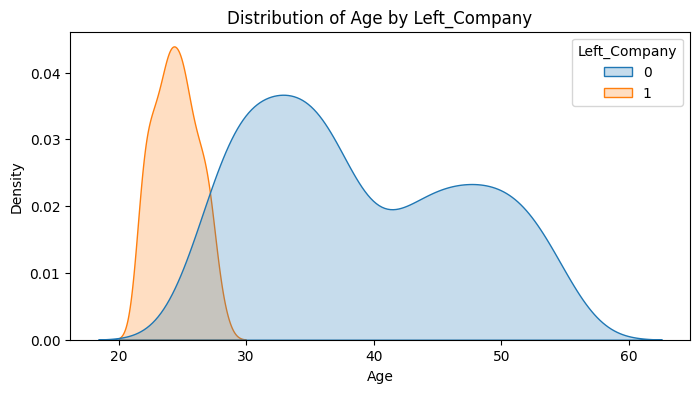

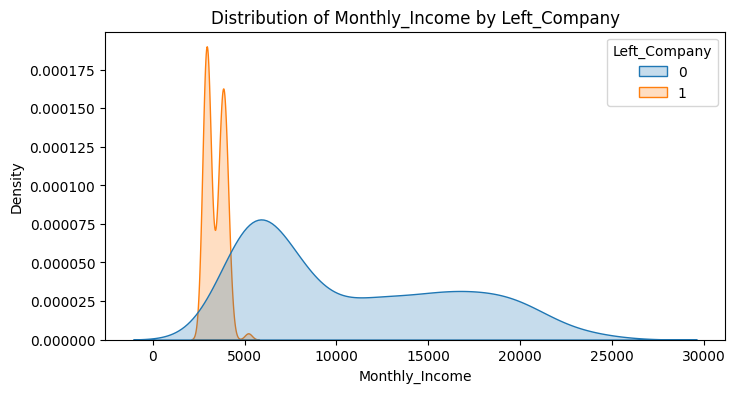

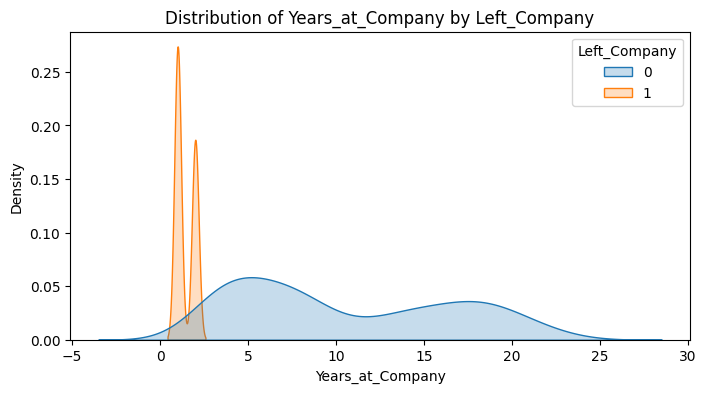

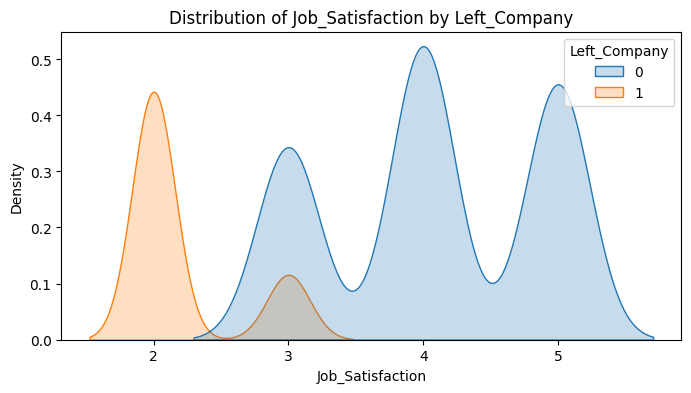

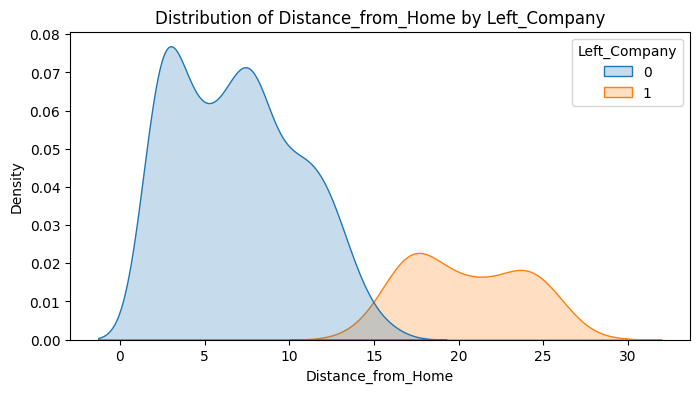

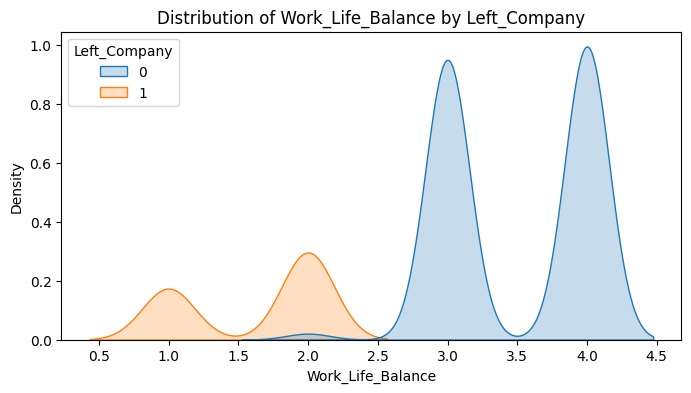

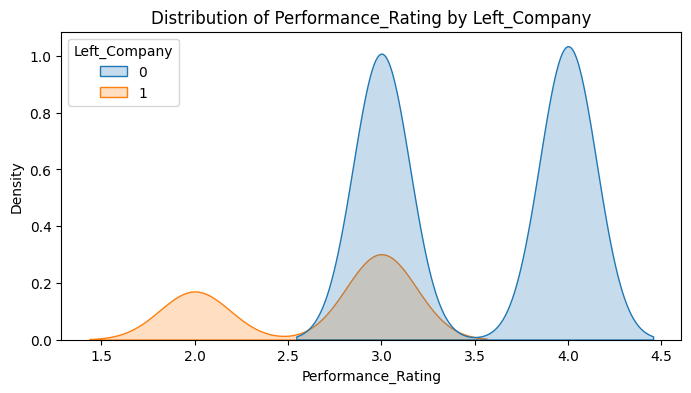

/tmp/ipython-input-3913975658.py:5: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(data=data, x=feature, hue='Left_Company', fill=True)


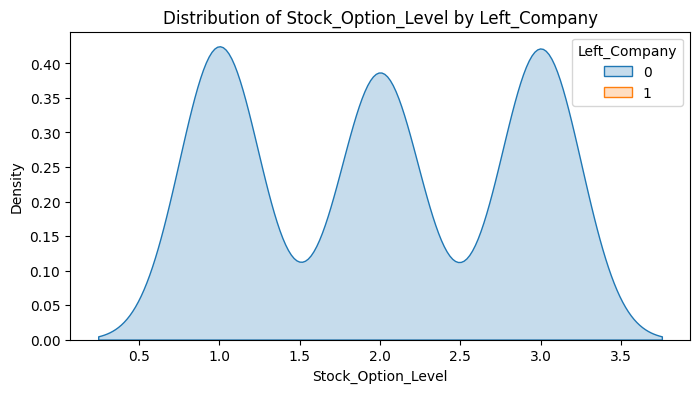

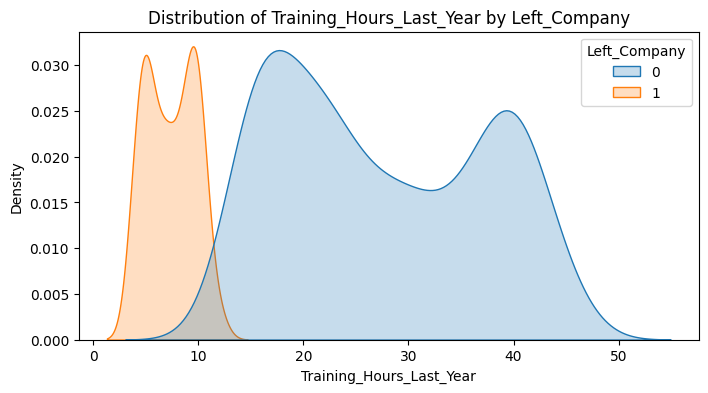

In [ ]:
numerical_features = ['Age', 'Monthly_Income', 'Years_at_Company', 'Job_Satisfaction', 'Distance_from_Home','Work_Life_Balance', 'Performance_Rating','Stock_Option_Level','Training_Hours_Last_Year', ]

for feature in numerical_features:
    plt.figure(figsize=(8,4))
    sns.kdeplot(data=data, x=feature, hue='Left_Company', fill=True)
    plt.title(f'Distribution of {feature} by Left_Company')
    plt.show()


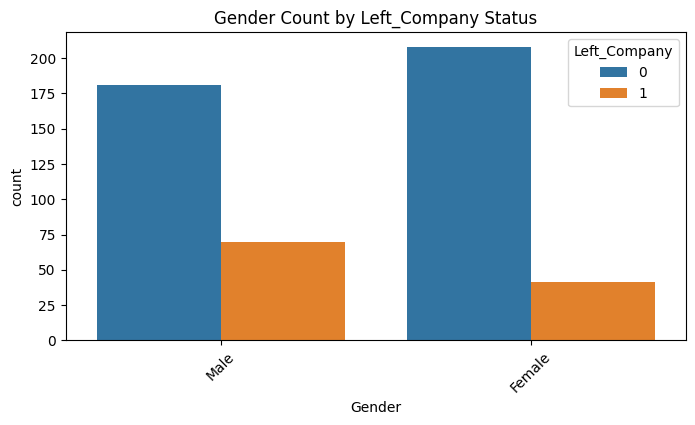

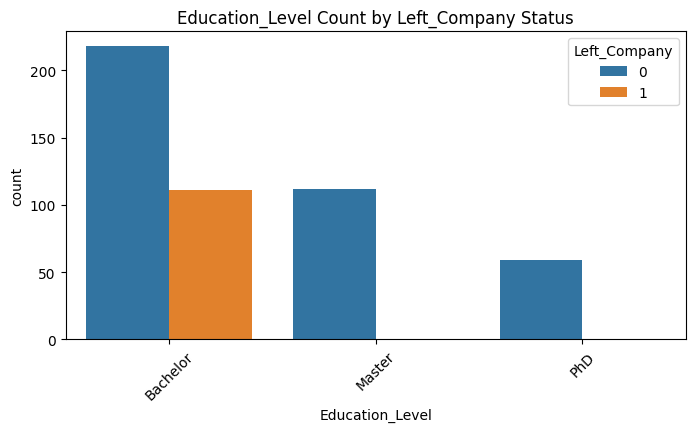

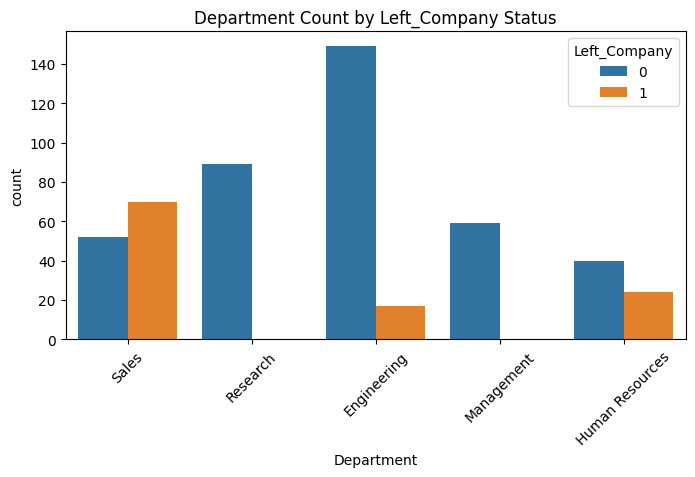

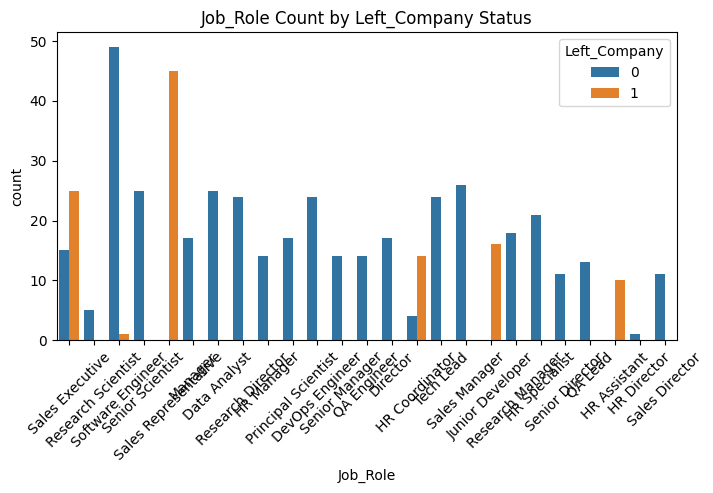

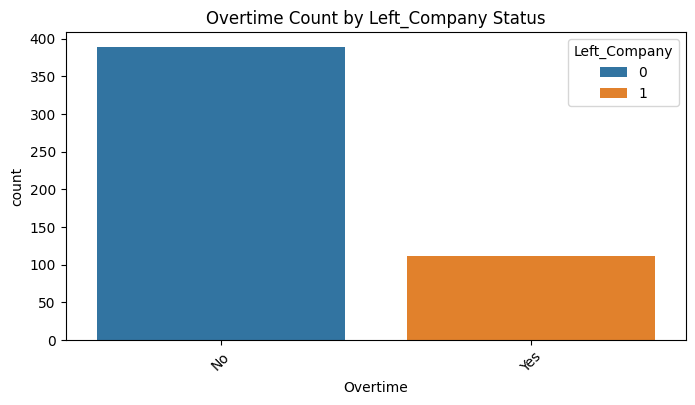

In [ ]:
#countplots for the categorical features
categorical_features = ['Gender', 'Education_Level', 'Department', 'Job_Role', 'Overtime']

for feature in categorical_features:
    plt.figure(figsize=(8,4))
    sns.countplot(data=data, x=feature, hue='Left_Company')
    plt.title(f'{feature} Count by Left_Company Status')
    plt.xticks(rotation=45)
    plt.show()


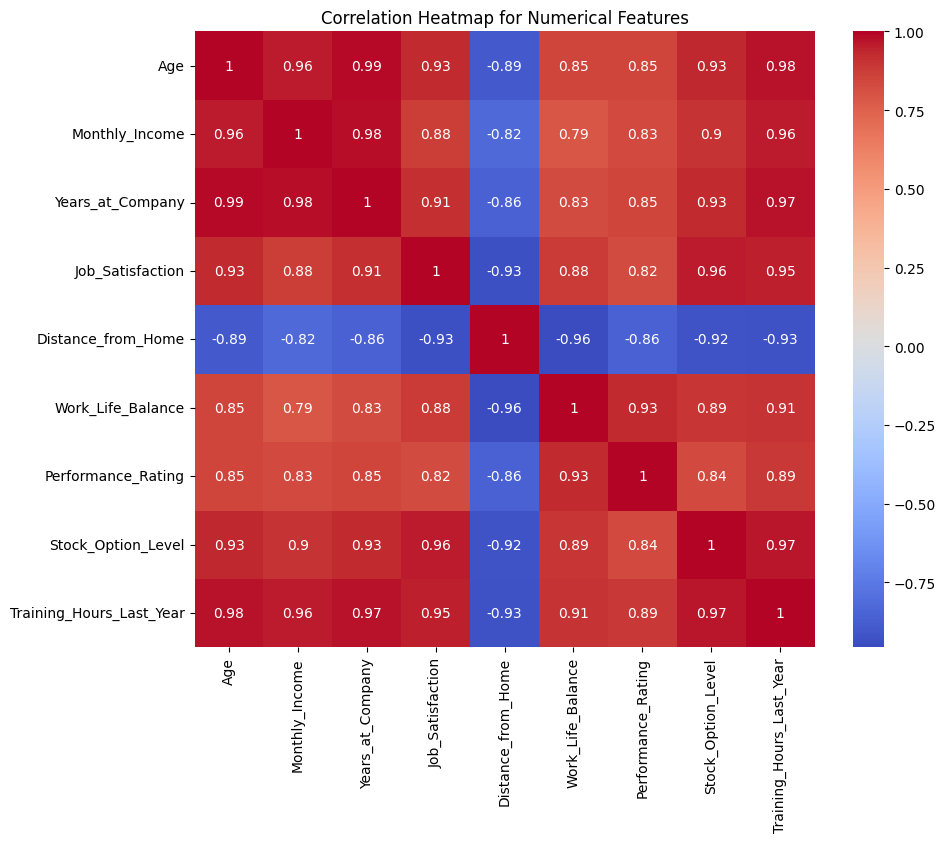

In [ ]:
#creating the corelation heatmap
plt.figure(figsize=(10,8))
sns.heatmap(data[numerical_features].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap for Numerical Features')
plt.show()


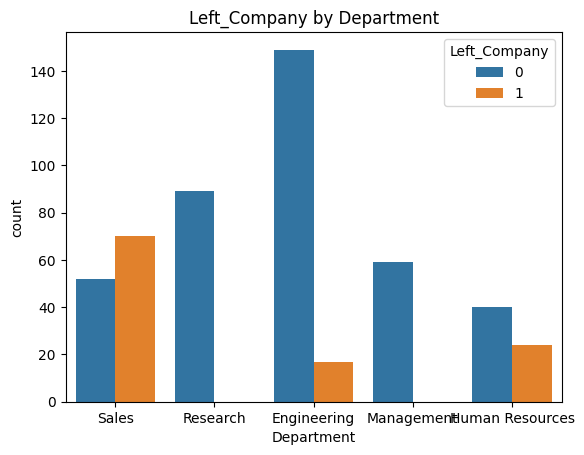

In [ ]:
#
sns.countplot(data=data, x='Department', hue='Left_Company')
plt.title('Left_Company by Department')
plt.show()


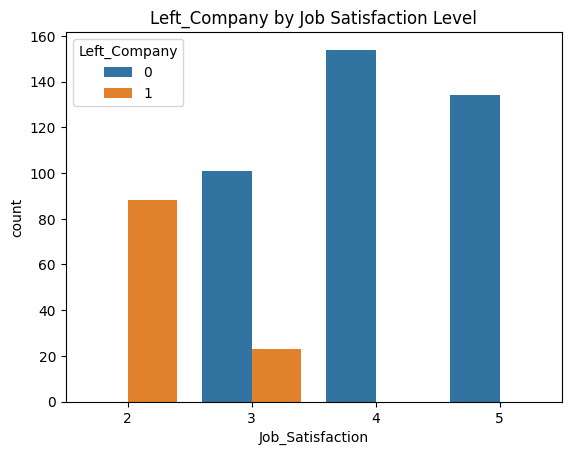

In [ ]:
sns.countplot(data=data, x='Job_Satisfaction', hue='Left_Company')
plt.title('Left_Company by Job Satisfaction Level')
plt.show()


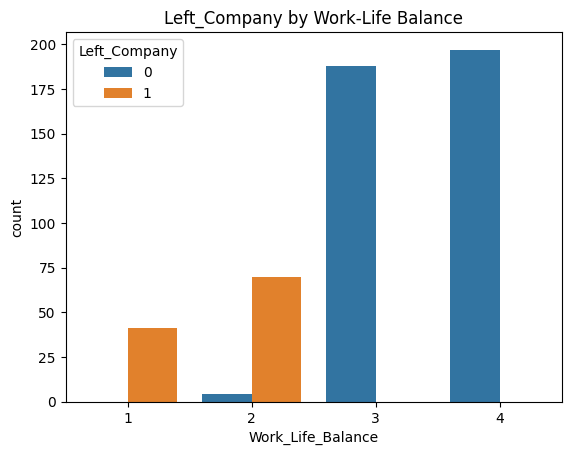

In [ ]:
sns.countplot(data=data, x='Work_Life_Balance', hue='Left_Company')
plt.title('Left_Company by Work-Life Balance')
plt.show()


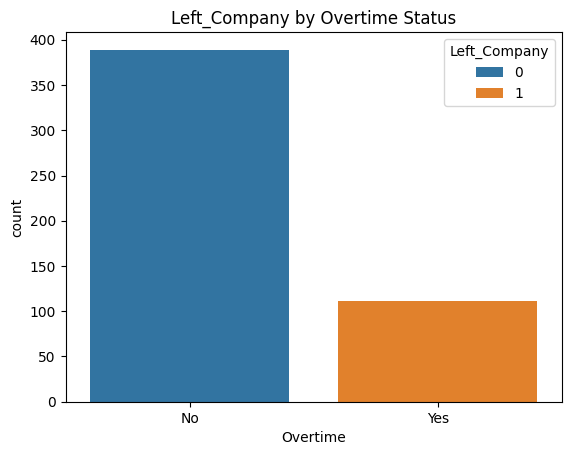

In [ ]:
sns.countplot(data=data, x='Overtime', hue='Left_Company')
plt.title('Left_Company by Overtime Status')
plt.show()


In [ ]:
#mapping the gender column to represent female 0 and male 1
data['Gender'] = data['Gender'].map({'Female': 0, 'Male': 1})

In [ ]:
#mapping the educational level
data['Education_Level'] = data['Education_Level'].map({'Bachelor': 0, 'Master': 1, 'PhD': 2})

In [ ]:
#encoding the job role column using the label encoder
from sklearn.preprocessing import LabelEncoder
# Creating encoder
label_job = LabelEncoder()
# Fitting and transforming the Job_Role column
data['Job_Role'] = label_job.fit_transform(data['Job_Role'])

In [ ]:
#fitting and transforming the department column using label encoder
label_dept = LabelEncoder()
data['Department'] = label_dept.fit_transform(data['Department'])


In [ ]:
#mapping the overtime column
data['Overtime'] = data['Overtime'].map({'No': 0, 'Yes': 1})

In [ ]:
data.head()

,Employee_ID,Age,Gender,Education_Level,Department,Job_Role,Years_at_Company,Monthly_Income,Distance_from_Home,Work_Life_Balance,Job_Satisfaction,Performance_Rating,Overtime,Stock_Option_Level,Training_Hours_Last_Year,Left_Company
0,1,32,1,0,4,17,3,4500,8,3,4,3,0,1,20,0
1,2,45,0,1,3,15,12,8500,5,4,5,4,0,2,35,0
2,3,28,1,0,0,23,2,5200,15,2,2,3,1,0,10,1
3,4,38,0,2,3,22,8,9800,3,4,4,4,0,3,40,0
4,5,25,1,0,4,19,1,3200,22,2,2,3,1,0,8,1


In [ ]:
#dropping the employee id column as it has 0 impact
data1 = data.drop(['Employee_ID'], axis=1)
data1.head()

,Age,Gender,Education_Level,Department,Job_Role,Years_at_Company,Monthly_Income,Distance_from_Home,Work_Life_Balance,Job_Satisfaction,Performance_Rating,Overtime,Stock_Option_Level,Training_Hours_Last_Year,Left_Company
0,32,1,0,4,17,3,4500,8,3,4,3,0,1,20,0
1,45,0,1,3,15,12,8500,5,4,5,4,0,2,35,0
2,28,1,0,0,23,2,5200,15,2,2,3,1,0,10,1
3,38,0,2,3,22,8,9800,3,4,4,4,0,3,40,0
4,25,1,0,4,19,1,3200,22,2,2,3,1,0,8,1


In [ ]:
#separating the x and y (dependent and the independent variables)
X = data.drop('Left_Company', axis=1)
Y = data['Left_Company']

In [ ]:
#splitting the dataset to train and test
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.2, random_state=42)

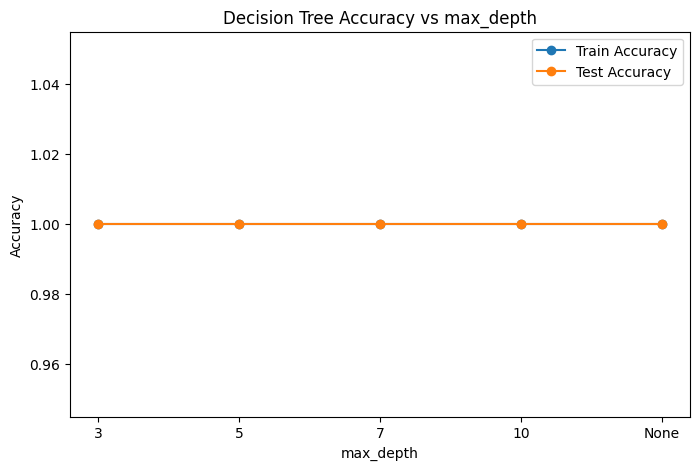

In [ ]:
#Model Building Build and evaluate the following classifiers:
#starting with the decision tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Tracking results
max_depth_values = [3, 5, 7, 10, None]
train_acc = []
test_acc = []

for depth in max_depth_values:
    decision_tree = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=0)
    decision_tree.fit(X_train, Y_train)

    # Calculating Accuracy
    train_acc.append(decision_tree.score(X_train, Y_train))
    test_acc.append(decision_tree.score(X_test, Y_test))

# Visualize accuracy vs max_depth
plt.figure(figsize=(8,5))
plt.plot([str(d) for d in max_depth_values], train_acc, marker='o', label='Train Accuracy')
plt.plot([str(d) for d in max_depth_values], test_acc, marker='o', label='Test Accuracy')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree Accuracy vs max_depth')
plt.legend()
plt.show()


In [ ]:
#creating the best decision tree model
best_dt = DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=0)
best_dt.fit(X_train, Y_train)

# Evaluate
y_pred_dt = best_dt.predict(X_test)
print("Decision Tree Accuracy:", accuracy_score(Y_test, y_pred_dt))
print(classification_report(Y_test, y_pred_dt))

Decision Tree Accuracy: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        87
           1       1.00      1.00      1.00        13

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



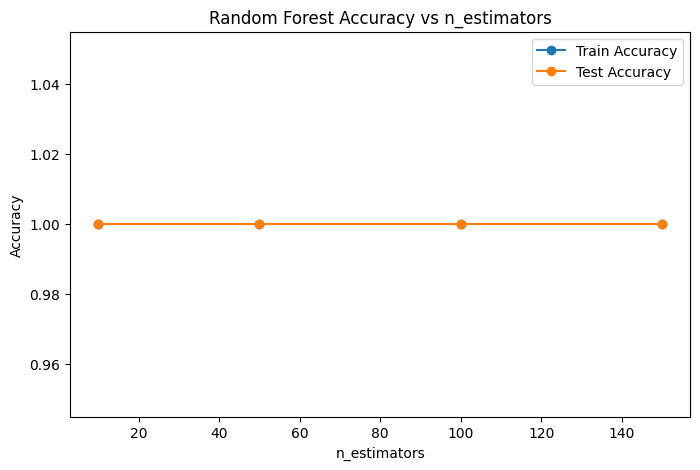

In [ ]:
#Training the random forest model
from sklearn.ensemble import RandomForestClassifier
n_estimators_values = [10, 50, 100, 150]
rf_train_acc = []
rf_test_acc = []

for n in n_estimators_values:
    rf = RandomForestClassifier(n_estimators=n, criterion='entropy', random_state=0)
    rf.fit(X_train, Y_train)
    rf_train_acc.append(rf.score(X_train, Y_train))
    rf_test_acc.append(rf.score(X_test, Y_test))

# Plot
plt.figure(figsize=(8,5))
plt.plot(n_estimators_values, rf_train_acc, marker='o', label='Train Accuracy')
plt.plot(n_estimators_values, rf_test_acc, marker='o', label='Test Accuracy')
plt.xlabel('n_estimators')
plt.ylabel('Accuracy')
plt.title('Random Forest Accuracy vs n_estimators')
plt.legend()
plt.show()

In [ ]:
#Best random forest model
best_rf = RandomForestClassifier(n_estimators=100, criterion='entropy', random_state=0)  # Example n_estimators=100
best_rf.fit(X_train, Y_train)

y_pred_rf = best_rf.predict(X_test)
print("Random Forest Accuracy:", accuracy_score(Y_test, y_pred_rf))
print(classification_report(Y_test, y_pred_rf))

Random Forest Accuracy: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        87
           1       1.00      1.00      1.00        13

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



Top 5 DecisionTrees features:
 Overtime           1.0
Age                0.0
Employee_ID        0.0
Education_Level    0.0
Department         0.0
dtype: float64
Top 5 RandomForest features:
 Years_at_Company            0.188217
Training_Hours_Last_Year    0.180857
Overtime                    0.153874
Stock_Option_Level          0.127065
Work_Life_Balance           0.117381
dtype: float64


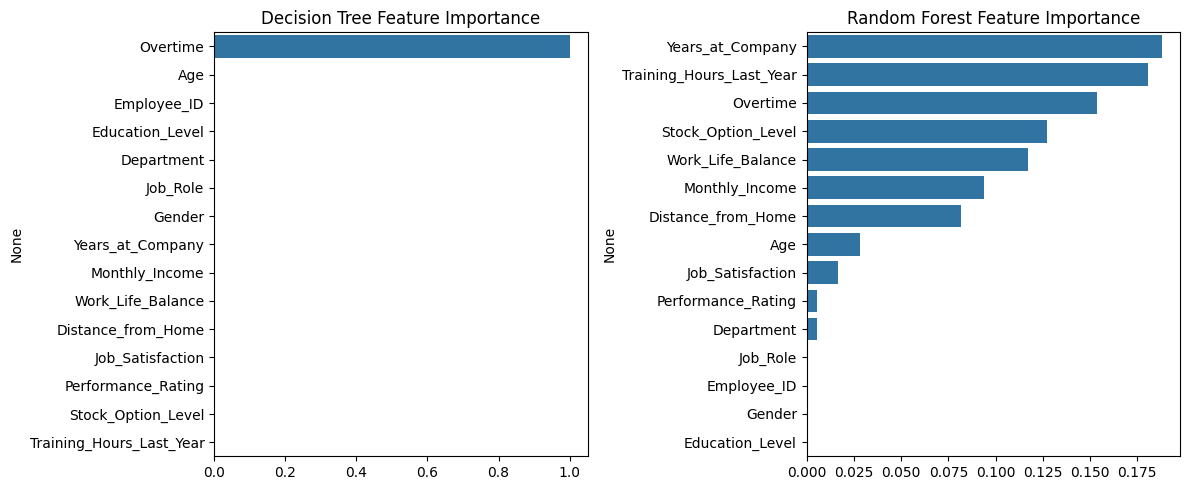

In [ ]:
#feature importance analysis
# Decision Tree Feature Importance
dt_features = pd.Series(best_dt.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Top 5 DecisionTrees features:\n", dt_features.head(5))

# Random Forest Feature Importance
rf_features = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Top 5 RandomForest features:\n", rf_features.head(5))

# Visualizing
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.barplot(x=dt_features.values, y=dt_features.index)
plt.title('Decision Tree Feature Importance')

plt.subplot(1,2,2)
sns.barplot(x=rf_features.values, y=rf_features.index)
plt.title('Random Forest Feature Importance')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Decision Tree Metrics
dt_metrics = {
    'Accuracy': accuracy_score(Y_test, y_pred_dt),
    'Precision': precision_score(Y_test, y_pred_dt),
    'Recall': recall_score(Y_test, y_pred_dt),
    'F1-Score': f1_score(Y_test, y_pred_dt)
}

# Random Forest Metrics
rf_metrics = {
    'Accuracy': accuracy_score(Y_test, y_pred_rf),
    'Precision': precision_score(Y_test, y_pred_rf),
    'Recall': recall_score(Y_test, y_pred_rf),
    'F1-Score': f1_score(Y_test, y_pred_rf)
}

# Create comparison table
comparison = pd.DataFrame([dt_metrics, rf_metrics], index=['Decision Tree', 'Random Forest'])
print(comparison)

               Accuracy  Precision  Recall  F1-Score
Decision Tree       1.0        1.0     1.0       1.0
Random Forest       1.0        1.0     1.0       1.0


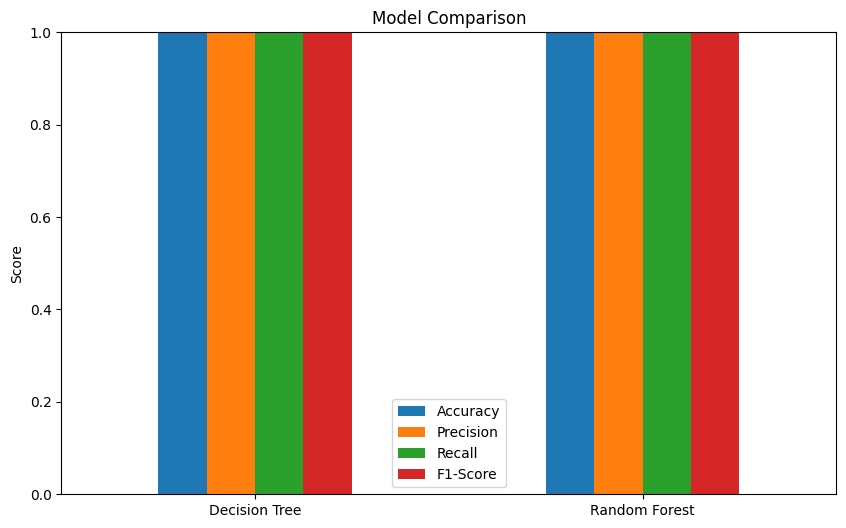

In [ ]:
comparison.plot(kind='bar', figsize=(10,6))
plt.title('Model Comparison')
plt.ylabel('Score')
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.show()

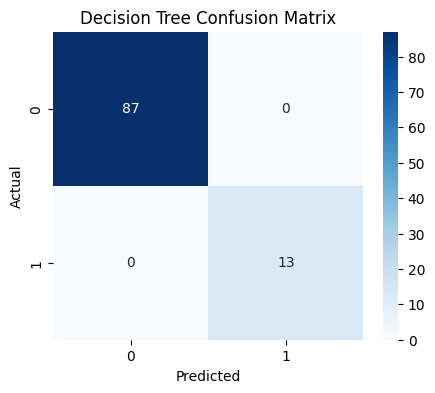

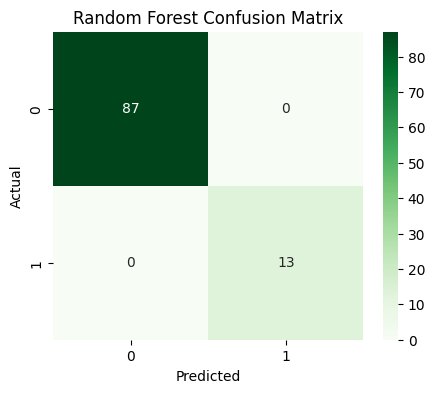

In [ ]:
# Decision Tree Confusion Matrix
cm_dt = confusion_matrix(Y_test, y_pred_dt)
plt.figure(figsize=(5,4))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues')
plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Random Forest Confusion Matrix
cm_rf = confusion_matrix(Y_test, y_pred_rf)
plt.figure(figsize=(5,4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens')
plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

**Key Features Influencing Employee Attrition**

The strength and feature importance from both Decision Tree and Random Forest, the most influential drivers of attrition appear to be:

Job Role

Department

Monthly Income

Years at Company

Distance from Home

Work-Life Balance

Stock Option Level

What's interesting is that many of these variables are interconnected. For example:

Income increases with tenure.

Satisfaction increases with stock options.

Commute distance negatively impacts satisfaction and balance.

This interconnected structure likely contributed to the model's perfect classification performance.

      Accuracy  Precision  Recall  F1-Score
Decision Tree       1.0        1.0     1.0       1.0

Random Forest       1.0        1.0     1.0       1.0

### Both models achieved perfect scores on the test set.

While this initially looks impressive, the correlation heatmap helps explain why:

The dataset has very strong linear and non-linear separability.

Many features move together in predictable patterns.

Tree-based models easily capture these relationships.

However, this also signals potential overfitting or limited generalization, especially if the dataset is small or artificially structured.

### Interpretation & Professional Reflection

This week reinforced something important for me:

When features are highly correlated, tree models can look “perfect” but real-world deployment requires caution.

The heatmap reveals multicollinearity across multiple predictors. While tree models handle this better than linear models, it means:

Some features may be redundant.

The model may rely heavily on a cluster of related signals.

Cross validation and larger datasets will be critical before deployment.

### Business Interpretation

If I step into the HR strategist mindset, here's what this means:

Long commute = high dissatisfaction risk

Low income + limited stock options = disengagement

Mid-tenure employees without progression = potential flight risk

Certain departments may structurally experience higher turnover

The data is telling a story - and it's not random.

Attrition here appears strongly linked to:

Structural job conditions

Compensation progression

Commute burden

Career growth signals

### Final Model Decision

Although both models show identical metrics, I would deploy:

### Random Forest

Because:

It generalizes better than a single tree.

It reduces variance.

It is more stable under new data.

It handles correlated predictors more robustly.